In [2]:
import cv2
import numpy as np
import math
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt

DATA_DIR = Path().resolve().parent / "data" / "qsd1_w3"
IMG_NAME = "00021.jpg"

IMG_SIZE = 672
GRID_SIZE = 4
BLOCK_SIZE = 8
N_COEFFS = 16

In [3]:
def show_images(*images, titles=None, cols=4, figsize=(7, 4), bgr=True):
    if not isinstance(images, (list, tuple)):
        images = [images]
    if titles is not None and not isinstance(titles, (list, tuple)):
        titles = [titles]

    n = len(images)
    cols = min(cols, n)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)

    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= n:
            continue

        img = images[i]

        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            if bgr:
                if img.shape[2] == 4:
                    img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA)
                else:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)

        if titles is not None and i < len(titles):
            ax.set_title(titles[i])

    plt.tight_layout()
    plt.show()

In [4]:
def zigzag_indices(n=8):
    return sorted(((i, j) for i in range(n) for j in range(n)),
                  key=lambda p: (p[0] + p[1], p[0] if (p[0] + p[1]) % 2 else p[1]))

def square_crop_and_resize(img, size=672):  # Multiple of 8,6,4,2 and near min side mean (645)
    height, width = img.shape[:2]
    side = min(width, height)

    top, left = (height - side) // 2, (width - side) // 2
    square_img = img[top:top + side, left:left + side]

    interpolation = cv2.INTER_AREA if size < side else cv2.INTER_CUBIC
    return cv2.resize(square_img, (size, size), interpolation=interpolation)

def split_blocks(img, block_size=8):
    """
    Splits an image into non-overlapping square blocks.

    img: image as a NumPy array (grayscale HxW or color HxWxC)
    block_size: side length of each block in pixels

    Returns an array of shape (rows, cols, block_size, block_size)
    or (rows, cols, block_size, block_size, C) for color images.
    """
    height, width = img.shape[:2]
    # Crop the leftover pixels so the size is a multiple of block_size
    img = img[:height - height % block_size, :width - width % block_size]

    height, width = img.shape[:2]
    rows, cols = height // block_size, width // block_size

    blocks = img.reshape(rows, block_size, cols, block_size, *img.shape[2:])
    blocks = blocks.swapaxes(1, 2)

    return blocks

def blocks_dct(blocks):
    shifted = np.ascontiguousarray(blocks, dtype=np.float32) - 128
    coeffs = np.empty_like(shifted)

    for i in range(shifted.shape[0]):
        for j in range(shifted.shape[1]):
            block = shifted[i, j]
            if block.ndim == 2:
                coeffs[i, j] = cv2.dct(block)
            else:
                for c in range(block.shape[2]):
                    coeffs[i, j, :, :, c] = cv2.dct(np.ascontiguousarray(block[:, :, c]))

    return coeffs

def keep_n_coeffs(coeffs, n=16):
    """
    Keeps the first n DCT coefficients of each block in zigzag order.

    coeffs: array of shape (rows, cols, bs, bs) or (rows, cols, bs, bs, channels)
    n: number of coefficients to keep (1 to bs*bs)

    Returns an array of shape (rows, cols, n, channels).
    """
    if coeffs.ndim == 4:
        coeffs = coeffs[..., np.newaxis]

    block_size = coeffs.shape[2]
    if not 1 <= n <= block_size * block_size:
        raise ValueError(f"n must be between 1 and {block_size * block_size}, got {n}")

    r, c = np.array(zigzag_indices(block_size)[:n]).T
    return coeffs[:, :, r, c]

def group_blocks(n_coeffs, grid_size):
    """Splits the blocks into grid_size x grid_size groups -> (grid_size**2, blocks_per_group, n, channels)."""
    rows, cols, n, channels = n_coeffs.shape
    cell_rows, cell_cols = rows // grid_size, cols // grid_size
    assert cell_rows > 0 and cell_cols > 0, f"Grid {grid_size} too big for {rows}x{cols} blocks"

    n_coeffs = n_coeffs[:cell_rows * grid_size, :cell_cols * grid_size]

    groups = n_coeffs.reshape(grid_size, cell_rows, grid_size, cell_cols, n, channels)
    return groups.swapaxes(1, 2).reshape(grid_size * grid_size, cell_rows * cell_cols, n, channels)

In [5]:
img = cv2.imread(DATA_DIR / IMG_NAME)
img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

square_img = square_crop_and_resize(img, IMG_SIZE)

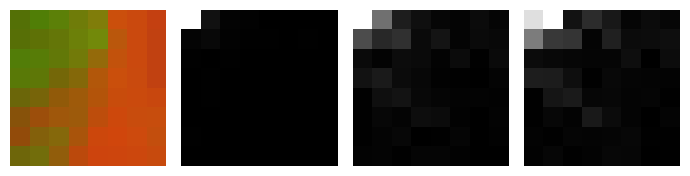

In [6]:
blocks = split_blocks(square_img, BLOCK_SIZE)
coeffs = blocks_dct(blocks)
coeffs = np.abs(coeffs)

block_i = 10
block_j = 42

show_images(
    blocks[block_i,block_j],
    coeffs[block_i,block_j,:,:,0],
    coeffs[block_i,block_j,:,:,1],
    coeffs[block_i,block_j,:,:,2]
)

In [7]:
n_coeffs = keep_n_coeffs(coeffs, N_COEFFS)
n_coeffs.shape

(84, 84, 16, 3)

In [8]:
block_groups = group_blocks(n_coeffs, GRID_SIZE)
block_groups.shape

(16, 441, 16, 3)

In [9]:
group_means = np.mean(block_groups, axis=1)
group_means.shape

(16, 16, 3)

In [10]:
group_means_sv = group_means[:,:,1:]
group_means_sv.shape

(16, 16, 2)